In [1]:
from kinetic_model.constants.energy_profile import EnergyBarriersSimplifyed, EnergyBarriers
from kinetic_model.simulation.run_reactor import ReactorSimulationChemisorptionSimplified, ReactorSimulationChemisorption
from kinetic_model.core.diffusion import Reaction_Diffusion
import seaborn as sns
import joblib
import numpy as np
import pandas as pd
import math
from copy import deepcopy
import re

from kinetic_model.simulation.reaction_list_creator import (
    make_reaction_list_chemisorp_simplified,
    prepare_constants_chemisorp_simplified
)


class ReactorStream(ReactorSimulationChemisorptionSimplified):
    """
    A class to handle the reactor stream simulation.
    Inherits from ReactorSimulationChemisorption.
    """
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)

    def _build_solver(self):
        df, idx = self._make_dataframe()
        self._diffusion_rates = self._calc_diffusion_constants(df, idx)
        self._capacity = self._calc_capacity(df, idx)

        for key, _ in self._capacity.items():
            if 'out' in key:
                self._capacity[key] = 1e6


        self.consts = prepare_constants_chemisorp_simplified(
            self.barrier_params,
            temperature=self.T
        )
        self._reactions = make_reaction_list_chemisorp_simplified(
            n_max=self.N,
            consts=self.consts,
            diffusion_rates=self._diffusion_rates,
            include_diffusion=self.include_diffusion

        )

        for i, reaction in enumerate(self._reactions):
            string = reaction[0].replace('<D>', 'D>')
            self._reactions[i] = (string, reaction[1], reaction[2], )

        return Reaction_Diffusion(reactions=self._reactions, capacity=self._capacity, 
                                  fixed_concentrations=['C2', 'C2_out'])


def time_distribution(result: pd.DataFrame) -> pd.DataFrame:
    """
    Compute per-time distribution P(C_n | n>2) from a wide time series.

    Input
    -----
    result : DataFrame with columns like:
        time, C2, C2_out, C4, C4_out, C6, C6_out, ...

    Output
    ------
    DataFrame with columns:
        time, n, probability   (only n > 2)

    Notes
    -----
    - Uses only in-reactor columns matching exactly 'C\\d+' (excludes '*_out').
    - If total concentration of n>2 at a time is 0, probabilities are NaN for that time.
    """
    if 'time' not in result.columns:
        raise ValueError("Input must contain a 'time' column.")

    # Keep only exact Cn columns (exclude *_out etc.)
    cn_cols = [c for c in result.columns if re.fullmatch(r'C\d+', c)]

    if not cn_cols:
        return pd.DataFrame(columns=['time', 'n', 'probability'])

    # Wide -> long
    long = (result[['time'] + cn_cols]
            .melt(id_vars='time', var_name='species', value_name='concentration'))

    # Extract n
    long['n'] = long['species'].str.extract(r'(\d+)').astype(int)

    # Totals per time over n>2
    totals = (long.loc[long['n'] > 2]
                    .groupby('time', as_index=False)['concentration']
                    .sum()
                    .rename(columns={'concentration': 'total_conc'}))

    # Merge totals, compute probabilities, filter n>2
    out = (long.merge(totals, on='time', how='left')
                .assign(probability=lambda d: d['concentration'] / d['total_conc'])
                .loc[lambda d: d['n'] > 2, ['time', 'n', 'probability']]
                .sort_values(['time', 'n'])
                .reset_index(drop=True))

    return out


def tail_slope_prob_per_n(dist: pd.DataFrame, tail_frac: float = 0.10) -> pd.DataFrame:
    """
    Compute d(probability)/dt for each n over the last `tail_frac` of the simulation time.

    Parameters
    ----------
    dist : pd.DataFrame
        Long-form dataframe with columns: ['time', 'n', 'probability'].
    tail_frac : float, optional (default=0.10)
        Fraction of the *time span* to use from the end (e.g., 0.10 = last 10%).

    Returns
    -------
    pd.DataFrame with columns:
        - n : int
        - slope : float  (units: probability per time)
        - window_start : float  (time at which the tail window starts)
        - window_end : float    (max time)
        - points_used : int     (# of points used in the fit for that n)

    Notes
    -----
    - Uses np.polyfit on (time, probability) within the tail window, after dropping NaNs.
    - If fewer than 2 points for an n in the tail window, slope is NaN.
    """
    required_cols = {'time', 'n', 'probability'}
    missing = required_cols - set(dist.columns)
    if missing:
        raise ValueError(f"Input distribution is missing columns: {missing}")

    # Ensure proper dtypes
    d = dist[['time', 'n', 'probability']].copy()
    d['time'] = pd.to_numeric(d['time'], errors='coerce')
    d['n'] = pd.to_numeric(d['n'], errors='coerce', downcast='integer')
    d['probability'] = pd.to_numeric(d['probability'], errors='coerce')

    # Determine tail time window using the overall time span
    t_min = d['time'].min()
    t_max = d['time'].max()
    if not np.isfinite(t_min) or not np.isfinite(t_max):
        return pd.DataFrame(columns=['n', 'slope', 'window_start', 'window_end', 'points_used'])

    window_start = t_min + (1 - tail_frac) * (t_max - t_min)
    tail = d[(d['time'] >= window_start) & (d['time'] <= t_max)]

    results = []
    for n_val, g in tail.groupby('n', dropna=True):
        g = g.dropna(subset=['time', 'probability']).sort_values('time')
        if len(g) < 2:
            slope = np.nan
            points_used = len(g)
        else:
            # Linear fit: probability ~ a*time + b; slope = a
            a, b = np.polyfit(g['time'].values, g['probability'].values, deg=1)
            slope = float(a)
            points_used = len(g)

        results.append({
            'n': int(n_val) if pd.notna(n_val) else np.nan,
            'slope': slope,
            'window_start': float(window_start),
            'window_end': float(t_max),
            'points_used': int(points_used),
        })

    return pd.DataFrame(results).sort_values('n').reset_index(drop=True)


def check_convergance(ts, error_threshold=1e-2):
    distr = time_distribution(ts.reset_index(names=['time']))
    is_converged = bool(tail_slope_prob_per_n(distr, tail_frac=0.10).slope.abs().max() < error_threshold)
    if is_converged:
        return True
    return False


In [5]:
N = 16
temperature = 300  # Kelvin
pressure = 25  # bar
steps = 1e4
time = 10
diffusion = True  # Set to False to disable diffusion
particle_size = 1000  # nm
c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

C2_conc, C2_out_conc = c2_model.predict_absolute(np.array([pressure * 101325]), 
                                                 np.array([temperature])), \
                    c2_model.predict_out(np.array([pressure * 101325]), 
                                         np.array([temperature]))

energy_barriers = EnergyBarriersSimplifyed(
    temperature=temperature,
    pressure=pressure
)

reactor = ReactorSimulationChemisorptionSimplified(
    N=N,
    T=temperature,
    pressure=pressure,
    L=particle_size,
    time_hours=time,
    n_steps=int(steps),
    diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
    ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
    energy_model=energy_barriers,
    initial_concs={'CatC2(C2)': 1e-2, 'C2': C2_conc[0], 'C2_out': C2_out_conc[0]},
    include_diffusion=diffusion
)


reactor.solver = reactor._build_solver()
print(r"\begin{table}[h]")
print(r"\centering")
print(r"\begin{tabular}{lcc}")
print(r"\hline")
print(r"Reaction & $k_\mathrm{f}$ & $k_\mathrm{b}$ \\")
print(r"\hline")

for reaction, kf, kb in reactor._reactions:
    print(f"{reaction} & {kf:.2e} & {kb:.2e} \\\\")

print(r"\hline")
print(r"\end{tabular}")
print(r"\caption{Forward and backward rate constants for all elementary reactions.}")
print(r"\label{tab:rates}")
print(r"\end{table}") # CatC6(C2) + C2 <-> CatC2(C2) + C6 & 2.25e-02 & 9.24e-02 \\

\begin{table}[h]
\centering
\begin{tabular}{lcc}
\hline
Reaction & $k_\mathrm{f}$ & $k_\mathrm{b}$ \\
\hline
CatC2(C2) + C2 <-> CatC4(C2) & 3.58e-02 & 2.24e-12 \\
CatC4(C2) + C2 <-> CatC6(C2) & 4.54e-01 & 6.97e-13 \\
CatC6(C2) + C2 <-> CatC8(C2) & 6.87e-02 & 1.57e-12 \\
CatC8(C2) + C2 <-> CatC10(C2) & 6.87e-02 & 1.57e-12 \\
CatC10(C2) + C2 <-> CatC12(C2) & 6.87e-02 & 1.57e-12 \\
CatC12(C2) + C2 <-> CatC14(C2) & 6.87e-02 & 1.57e-12 \\
CatC14(C2) + C2 <-> CatC16(C2) & 6.87e-02 & 1.57e-12 \\
CatC4(C2) + C2 <-> CatC2(C2) + C4 & 8.57e-02 & 3.70e-02 \\
CatC6(C2) + C2 <-> CatC2(C2) + C6 & 8.98e-03 & 3.70e-02 \\
CatC8(C2) + C2 <-> CatC2(C2) + C8 & 8.98e-03 & 3.70e-02 \\
CatC10(C2) + C2 <-> CatC2(C2) + C10 & 8.98e-03 & 3.70e-02 \\
CatC12(C2) + C2 <-> CatC2(C2) + C12 & 8.98e-03 & 3.70e-02 \\
CatC14(C2) + C2 <-> CatC2(C2) + C14 & 8.98e-03 & 3.70e-02 \\
CatC16(C2) + C2 <-> CatC2(C2) + C16 & 8.98e-03 & 3.70e-02 \\
C2 <D> C2_out & 1.90e+06 & 1.90e+06 \\
C4 <D> C4_out & 8.17e+05 & 8.17e+05 \\
C6 <D> 

np.float64(4.0)

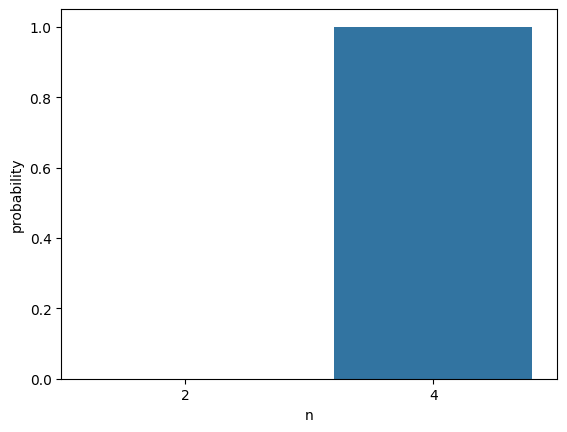

In [19]:
N = 4
temperature = 300  # Kelvin
pressure = 1  # bar
steps = 1e4
time = 10
diffusion = True  # Set to False to disable diffusion
particle_size = 1000  # nm
c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

C2_conc, C2_out_conc = c2_model.predict_absolute(np.array([pressure * 101325]), 
                                                 np.array([temperature])), \
                    c2_model.predict_out(np.array([pressure * 101325]), 
                                         np.array([temperature]))

energy_barriers = EnergyBarriersSimplifyed(
    temperature=temperature,
    pressure=pressure
)

reactor = ReactorSimulationChemisorptionSimplified(
    N=N,
    T=temperature,
    pressure=pressure,
    L=particle_size,
    time_hours=time,
    n_steps=int(steps),
    diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
    ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
    energy_model=energy_barriers,
    initial_concs={'CatC2(C2)': 1e-2, 'C2': C2_conc[0], 'C2_out': C2_out_conc[0]},
    include_diffusion=diffusion
)


reactor.solver = reactor._build_solver()

def max_constant(reactions):
    return np.max([i[1:] for i in reactions])

def normilize_constants(reactions, r_max=1e6):
    factor = r_max/max_constant(reactions)
    if factor >=1:
        factor = 1
    for i in range(len(reactions)):
        reactions[i] = (reactions[i][0], reactions[i][1] * factor, reactions[i][2] * factor)
    return factor

def remove_back_ins(reactions, N):
    number_of_insertions = N//2 - 2
    for cnt, i in enumerate(reactions):
        if cnt > number_of_insertions:
            break
        reactions[cnt] = (i[0].replace('<->', '->'), i[1], i[2])

def slowdawn_back_ins(reactions, N, order):
    number_of_insertions = N//2 - 2
    for cnt, i in enumerate(reactions):
        if cnt > number_of_insertions:
            break
        reactions[cnt] = (i[0], i[1], i[2]*10**(-order))

def check_errors(ts):
    return all(ts.min() > -1e-2)

factor = normilize_constants(reactor._reactions, r_max=1e6)
# remove_back_ins(reactor._reactions, reactor.N)
# slowdawn_back_ins(reactor._reactions, reactor.N, order=8)
reactor.time_hours /= factor

# for i in reactor._reactions:
#     print('{:35s} {:5.2e} {:5.2e}'.format(*i))

distr, ts = reactor.run(build_solver=False)

sns.barplot(data=distr, x='n', y='probability')
check_convergance(ts, error_threshold=1e-6)
np.round(np.sum(distr.n * distr.probability))

In [20]:
from copy import deepcopy
reactions_diff = deepcopy(reactor.solver.reaction_dict)



In [21]:
import numpy as np

def species_to_latex(name):
    """Wrap species name in [ ... ] with math-safe formatting."""
    return f"[\\mathrm{{{name}}}]"

def term_to_latex(reactants, coeff):
    """Convert ((A,B), coefficient) into latex like: -0.12 [A][B]."""
    # Build product [A][B][C]
    prod = "".join(species_to_latex(r) for r in reactants)

    # Format coefficient with reasonable precision
    coeff_str = f"{coeff:.6g}"  # scientific/float auto format

    # Add multiplication if needed
    if prod:
        return f"{coeff_str} \\, {prod}"
    else:
        return coeff_str

def ode_dict_to_latex(ode_dict):
    """Convert your full ODE dict into LaTeX align equations."""
    lines = []
    for species, terms in ode_dict.items():
        lhs = f"\\frac{{d{species_to_latex(species)}}}{{dt}}"
        
        # Build RHS
        rhs_terms = [term_to_latex(reactants, coeff) 
                     for reactants, coeff in terms]
        rhs = " \\\\ &\quad + ".join(rhs_terms)
        
        eq = f"{lhs} &= {rhs}"
        lines.append(eq)
    
    # Return combined align block
    latex = "\\begin{align}\n" + "\\\\\n".join(lines) + "\n\\end{align}"
    return latex

# Example usage:
print(ode_dict_to_latex(reactions_diff))  # paste dict here


\begin{align}
\frac{d[\mathrm{CatC2(C2)}]}{dt} &= -0.0187876 \, [\mathrm{CatC2(C2)}][\mathrm{C2}] \\ &\quad + 2.94951e-11 \, [\mathrm{CatC4(C2)}] \\ &\quad + 1.1263 \, [\mathrm{CatC4(C2)}][\mathrm{C2}] \\ &\quad + -0.485725 \, [\mathrm{CatC2(C2)}][\mathrm{C4}]\\
\frac{d[\mathrm{C2}]}{dt} &= -0.0187876 \, [\mathrm{CatC2(C2)}][\mathrm{C2}] \\ &\quad + 2.94951e-11 \, [\mathrm{CatC4(C2)}] \\ &\quad + -0.23838 \, [\mathrm{CatC4(C2)}][\mathrm{C2}] \\ &\quad + 9.16189e-12 \, [\mathrm{CatC6(C2)}] \\ &\quad + -1.1263 \, [\mathrm{CatC4(C2)}][\mathrm{C2}] \\ &\quad + 0.485725 \, [\mathrm{CatC2(C2)}][\mathrm{C4}] \\ &\quad + -492727 \, [\mathrm{C2}] \\ &\quad + 1.04337e+07 \, [\mathrm{C2_out}]\\
\frac{d[\mathrm{CatC4(C2)}]}{dt} &= 0.0187876 \, [\mathrm{CatC2(C2)}][\mathrm{C2}] \\ &\quad + -2.94951e-11 \, [\mathrm{CatC4(C2)}] \\ &\quad + -0.23838 \, [\mathrm{CatC4(C2)}][\mathrm{C2}] \\ &\quad + 9.16189e-12 \, [\mathrm{CatC6(C2)}] \\ &\quad + -1.1263 \, [\mathrm{CatC4(C2)}][\mathrm{C2}] \\ &\quad + 

<>:30: SyntaxWarning: invalid escape sequence '\q'
<>:30: SyntaxWarning: invalid escape sequence '\q'
/tmp/ipykernel_14700/254244100.py:30: SyntaxWarning: invalid escape sequence '\q'
  rhs = " \\\\ &\quad + ".join(rhs_terms)


In [30]:
s = """

Single-atom catalysts (SACs) maximize atomic efficiency by presenting uniform, isolated metal sites that can be precisely embedded within metal organic frameworks (MOFs) pore architectures, making them ideal targets for computational catalysis. Modern electronic-structure methods enable increasingly accurate predictions of reaction energetics and catalytic performance.
Because of the complex interplay of catalytic reactions, topology, and mass transport, the influence of the framework remains poorly understood. This study showed to how multiscale kinetic model can handle with this complexity. Ethylene oligomerization in Ni-grafted NU-1000 was chosen as a good example where all kinetic effects are crucial. So far, we have integrated advanced DFT-derived transition-state rates corrected to TPSSh accuracy and combined with co-adsorption and diffusion effects to predict SAC performance under realistic reaction conditions. The simulations demonstrate that pressure–temperature conditions alone cannot describe catalytic performance; reactor mode, diffusion limitations, MOF particles size, and active-site density collectively determine the olefin distribution and reaction progression. This multiscale framework bridges atomistic modeling and kinetic prediction, enabling rational design of MOF-supported catalysts.


"""

len(list(filter(lambda x: len(x)>3, s.split())))

130

In [11]:
N = 2
temperature = 450  # Kelvin
pressure = 1  # bar
steps = 1e4
time = 1e-8
diffusion = True  # Set to False to disable diffusion
particle_size = 10000  # nm
c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

C2_conc, C2_out_conc = c2_model.predict_absolute(np.array([pressure * 101325]), 
                                                 np.array([temperature])), \
                    c2_model.predict_out(np.array([pressure * 101325]), 
                                         np.array([temperature]))

energy_barriers = EnergyBarriersSimplifyed(
    temperature=temperature,
    pressure=pressure
)

reactor = ReactorSimulationChemisorptionSimplified(
    N=N,
    T=temperature,
    pressure=pressure,
    L=particle_size,
    time_hours=time,
    n_steps=int(steps),
    diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
    ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
    energy_model=energy_barriers,
    initial_concs={'CatC2(C2)': 1e-2, 'C2': C2_conc[0], 'C2_out': 0},
    include_diffusion=diffusion
)


reactor.solver = reactor._build_solver()



factor = normilize_constants(reactor._reactions, r_max=1e6)
# remove_back_ins(reactor._reactions, reactor.N)
# slowdawn_back_ins(reactor._reactions, reactor.N, order=8)
reactor.time_hours /= factor
reactor._reactions = [reactor._reactions[-1]]
for i in reactor._reactions:
    print('{:35s} {:5.2e} {:5.2e}'.format(*i))

(reactor._capacity['C2']/reactor._capacity['C2_out']) / (C2_conc[0] / C2_out_conc[0])

C2 <D> C2_out                       1.72e+02 1.72e+02


np.float64(1.0250549470855563)

np.float64(4.0)

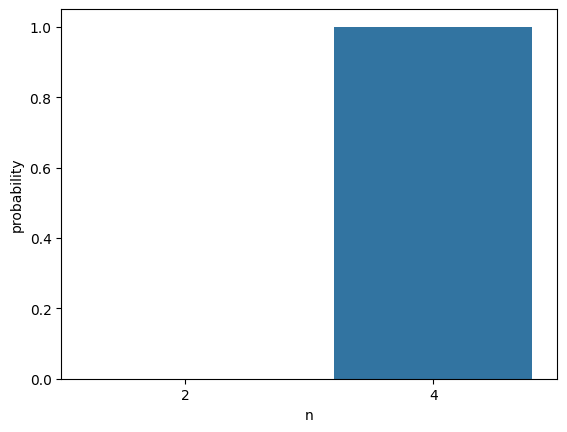

In [12]:
distr, ts = reactor.run(build_solver=False)

sns.barplot(data=distr, x='n', y='probability')
check_convergance(ts, error_threshold=1e-6)
np.round(np.sum(distr.n * distr.probability))

<Axes: xlabel='time'>

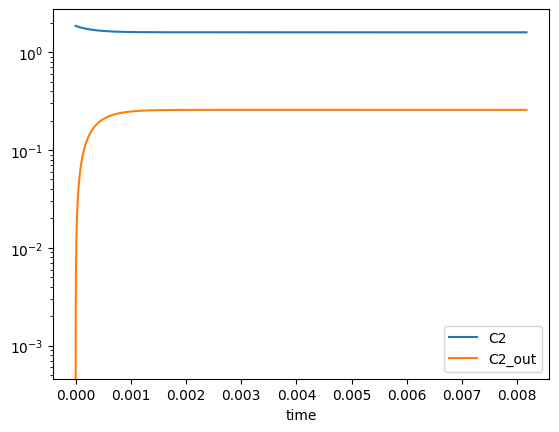

In [13]:
ts.reset_index(names=['time']).plot(x='time', y=['C2', 'C2_out'], logy=True)

## Generate data

In [3]:
import os
from tqdm import tqdm
import warnings
from IPython.display import clear_output
from func_timeout import func_timeout, FunctionTimedOut
from itertools import product
from joblib import Parallel, delayed
from tqdm_joblib import tqdm_joblib
from joblib import Parallel, delayed
# from tqdm.auto import tqdm
import numpy as np
import os


c2_model = joblib.load('../data/adsorption/pt_poly_model.pkl')

def get_distr(N, temperature, pressure, steps, time, diffusion, stream, ps, cat_conc, is_remove_back_ins=False):
    C2_conc, C2_out_conc = c2_model.predict_absolute(np.array([pressure * 101325]), 
                                                 np.array([temperature])), \
                    c2_model.predict_out(np.array([pressure * 101325]), 
                                         np.array([temperature]))


    energy_barriers = EnergyBarriersSimplifyed(
        temperature=temperature,
        pressure=pressure
    )

    reactor_model = ReactorStream if stream else ReactorSimulationChemisorptionSimplified
    reactor = reactor_model(
        N=N,
        T=temperature,
        pressure=pressure,
        L=ps,
        time_hours=time,
        n_steps=int(steps),
        diff_model_path='../data/processed/diffusion_extrap_place_holder_model.pkl',
        ads_model_path='../data/processed/knn_adsorption_slope_model.pkl',
        energy_model=energy_barriers,
        initial_concs={'CatC2(C2)': cat_conc, 'C2': C2_conc[0], 'C2_out': C2_out_conc[0]},
        include_diffusion=diffusion
    )
    
    reactor.solver = reactor._build_solver()
    norm_factor = normilize_constants(reactor._reactions, r_max=1e6)
    reactor.time_hours /= norm_factor
    if is_remove_back_ins:
        remove_back_ins(reactor._reactions, reactor.N)
    distr, ts = reactor.run(build_solver=False)
    ts.index = ts.index * norm_factor
    return distr, ts

# --- helper that runs INSIDE the timed worker and captures warnings there ---
def _get_distr_capture_warnings(args_tuple):
    import warnings
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always", category=Warning)
        distr, ts = get_distr(*args_tuple)  # must return (distr, ts)
    had_warnings = any(issubclass(msg.category, Warning) for msg in w)
    return distr, ts, had_warnings

N = 16
df = pd.DataFrame()
steps = 1e3
time = 10
temperatures = np.linspace(300, 600, 21)
pressures = np.linspace(1, 50, 11)

diffusion_modes = (True, False)
stream_modes = (True, False)
particle_sizes = (300, 1000, 1e4, 1e5, 1e6)#, 1e8, 1e12, 1e16)#(50, 300, 1000, 10000)
cat_concentration = (1e-2, 1e-1, 1e-3)
waiting_time = 30  # seconds
output_folder = 'files/modeling_C16_10h_corrected_151025V2/'
is_remove_back_ins = False
# --- Build task list (skip those already on disk) ---
def make_tail(temperature, pressure, N, diffusion, stream, ps, cat_conc):
    return f"temperature_{temperature}_pressure_{pressure}_N_{N}_diffusion_{diffusion}_stream_{stream}_particleSize_{ps}_cat_conc_{cat_conc}"

all_tasks = []
for temperature, ps, pressure, diffusion, stream, cat_conc in tqdm(product(
        temperatures, particle_sizes, pressures, diffusion_modes, stream_modes, cat_concentration)):
    if (not diffusion) and stream:
        continue
    tail = make_tail(temperature, pressure, N, diffusion, stream, ps, cat_conc)
    out_d = f"{output_folder}/distr_{tail}.pkl"
    out_t = f"{output_folder}/ts_{tail}.pkl"
    if os.path.exists(out_d):
        continue
    all_tasks.append((temperature, ps, pressure, diffusion, stream, cat_conc, is_remove_back_ins, tail))

print(f"Queued {len(all_tasks)} tasks")



# --- Worker: identical logic to your serial loop for one (T,ps,p,diff,stream,cat) ---
def run_one_task(task):
    temperature, ps, pressure, diffusion, stream, cat_conc, is_remove_back_ins, tail = task
    try:
        ok = False
        for time_increase in range(1):
            
            try:
                # grow total simulation time geometrically
                ttry = time * (10 ** time_increase)
                
                distr, ts, had_warnings = func_timeout(
                    waiting_time,
                    _get_distr_capture_warnings,
                    args=((N, temperature, pressure, steps, ttry, diffusion, stream, ps, cat_conc, is_remove_back_ins),)
                )

                had_warnings = not check_errors(ts)
                # any warning -> try longer ttry
                if had_warnings:
                     return {"tail": tail, "status": "skipped_errors"}
                # accept only if converged and warning-free
                if True:#check_convergance(ts, error_threshold=1e6):
                    ok = True
                    break
            except FunctionTimedOut:
                # ran longer than waiting_time -> try next (longer ttry)
                continue
            except Exception:
                # any error -> try next attempt
                continue
        
        if not ok:
            return {"tail": tail, "status": "skipped_no_convergence"}

        # write outputs (unique filenames -> safe in parallel)
        os.makedirs(output_folder, exist_ok=True)
        distr.to_pickle(f"{output_folder}/distr_{tail}.pkl")
        ts.to_pickle(f"{output_folder}/ts_{tail}.pkl")
        return {"tail": tail, "status": "ok"}

    except Exception as e:
        return {"tail": tail, "status": "error", "error": str(e)}


# run_one_task(all_tasks[0])

/home/aleksandr/miniconda3/envs/kinetic_model/lib/python3.12/site-packages/tqdm_joblib/__init__.py:4: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from tqdm.autonotebook import tqdm
13860it [00:00, 244720.26it/s]

Queued 10395 tasks


In [4]:
with tqdm_joblib(tqdm(total=len(all_tasks), desc="Simulating conditions")) as progress_bar:
    results = Parallel(n_jobs=-1, backend="loky", pre_dispatch="2*n_jobs")(
        delayed(run_one_task)(t) for t in all_tasks
    )


# (optional) quick summary
ok_cnt  = sum(r["status"]=="ok" for r in results)
skp_cnt = sum(r["status"]=="skipped_no_convergence" for r in results)
err_cnt = sum(r["status"]=="error" for r in results)
print(f"Done. ok={ok_cnt}, skipped={skp_cnt}, errors={err_cnt}")

Simulating conditions:   0%|          | 0/10395 [00:00<?, ?it/s]

 lsoda--  at t(=r1) and step size h(=r2), the error  
       test failed repeatedly or with abs(h) = hmin  
      in above,  r1 =  0.1879776625247D+07   r2 =  0.3986081733400D-05


 lsoda--  at t(=r1) and step size h(=r2), the error  
       test failed repeatedly or with abs(h) = hmin  
      in above,  r1 =  0.1106764664442D+09   r2 =  0.4929572047983D-03


 lsoda--  at t(=r1) and step size h(=r2), the error  
       test failed repeatedly or with abs(h) = hmin  
      in above,  r1 =  0.8805154161231D+09   r2 =  0.1018989327468D-02


 lsoda--  warning..internal t (=r1) and h (=r2) are  
       such that in the machine, t + h = t on the next step  
       (h = step size). solver will continue anyway  
      in above,  r1 =  0.7549182334240D+09   r2 =  0.2592222685932D-07
 lsoda--  warning..internal t (=r1) and h (=r2) are  
       such that in the machine, t + h = t on the next step  
       (h = step size). solver will continue anyway  
      in above,  r1 =  0.7549182334240D+09   r2 =  0.2592222685932D-07
 lsoda--  warning..internal t (=r1) and h (=r2) are  
       such that in the machine, t + h = t on the next step  
       (h = step size). solver will continue anyway  
      in above,  r1 =  0.7549182334240D+09   r2 =  0.2592222685932D-07
 lsoda--  warning..internal t (=r1) and h (=r2) are  
       such that in the machine, t + h = t on the next step  
       (h = step size). solver will continue anyway  
      in above,  r1 =  0.7549182334240D+09   r2 =  0.2592222685932D-07
 lsoda--  warning..internal t (=r1) 

...

 lsoda--  at t(=r1) and step size h(=r2), the error  
       test failed repeatedly or with abs(h) = hmin  
      in above,  r1 =  0.2009780476607D+07   r2 =  0.1013692286542D-04


capi_return is NULL
Call-back cb_f_in_lsoda__user__routines failed.


 lsoda--  warning..internal t (=r1) and h (=r2) are  
       such that in the machine, t + h = t on the next step  
       (h = step size). solver will continue anyway  
      in above,  r1 =  0.3230717101069D+10   r2 =  0.1178264272690D-06
 lsoda--  warning..internal t (=r1) and h (=r2) are  
       such that in the machine, t + h = t on the next step  
       (h = step size). solver will continue anyway  
      in above,  r1 =  0.3230717101069D+10   r2 =  0.1178264272690D-06
 lsoda--  warning..internal t (=r1) and h (=r2) are  
       such that in the machine, t + h = t on the next step  
       (h = step size). solver will continue anyway  
      in above,  r1 =  0.3230717101069D+10   r2 =  0.1178264272690D-06
 lsoda--  warning..internal t (=r1) and h (=r2) are  
       such that in the machine, t + h = t on the next step  
       (h = step size). solver will continue anyway  
      in above,  r1 =  0.3230717101069D+10   r2 =  0.1178264272690D-06
 lsoda--  warning..internal t (=r1) 

capi_return is NULL
Call-back cb_f_in_lsoda__user__routines failed.
capi_return is NULL
Call-back cb_f_in_lsoda__user__routines failed.
capi_return is NULL
Call-back cb_f_in_lsoda__user__routines failed.
capi_return is NULL
Call-back cb_f_in_lsoda__user__routines failed.
capi_return is NULL
Call-back cb_f_in_lsoda__user__routines failed.
capi_return is NULL
Call-back cb_f_in_lsoda__user__routines failed.
capi_return is NULL
Call-back cb_f_in_lsoda__user__routines failed.
capi_return is NULL
Call-back cb_f_in_lsoda__user__routines failed.
capi_return is NULL
Call-back cb_f_in_lsoda__user__routines failed.
capi_return is NULL
Call-back cb_f_in_lsoda__user__routines failed.
100%|██████████| 10395/10395 [13:11<00:00, 13.14it/s]

Done. ok=10328, skipped=67, errors=0
